<a href="https://colab.research.google.com/github/Tommys-laboratory1210/spatial-analysis-study/blob/main/lesson05/lesson05_local_moran.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

data = np.array([
    [10, 12, 11,  2,  3],
    [13, 15, 14,  4,  2],
    [11, 12, 13,  3,  4],
    [ 2,  3,  4, 14, 15],
    [ 3,  2,  4, 13, 12]
])

In [3]:
x = data.flatten()
mean_value = x.mean()
print(mean_value)

8.04


In [24]:
std_value = x.std()
z = (x - mean_value) / std_value

print(z)

[ 0.39264131  0.79329572  0.59296852 -1.2099763  -1.00964909  0.99362292
  1.39427732  1.19395012 -0.80932189 -1.2099763   0.59296852  0.79329572
  0.99362292 -1.00964909 -0.80932189 -1.2099763  -1.00964909 -0.80932189
  1.19395012  1.39427732 -1.00964909 -1.2099763  -0.80932189  0.99362292
  0.79329572]


In [26]:
# Spatial Weights Matrix
n = 5

W = np.zeros((n*n, n*n), dtype=int)

for r in range(n):
    for c in range(n):

        i = r*n + c

        neighbors = [
            (r-1, c),
            (r+1, c),
            (r, c-1),
            (r, c+1)
        ] # Rook contiguity

        for nr, nc in neighbors:
            if 0 <= nr < n and 0 <= nc < n:
                j = nr*n + nc
                W[i, j] = 1
print(W.shape)
print(W[0].reshape(5,5))

(25, 25)
[[0 1 0 0 0]
 [1 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


In [28]:
# Row-standardization W
W_mean = W / W.sum(axis=1, keepdims = True)
print(W_mean[0].reshape(5, 5))
print(W_mean[0].sum())

[[0.  0.5 0.  0.  0. ]
 [0.5 0.  0.  0.  0. ]
 [0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0. ]]
1.0


In [29]:
spatial_lag = W_mean @ z
print(spatial_lag.reshape(5,5)) # In each cell, we compare neighbor with total mean

[[ 0.89345932  0.79329572  0.25908985 -0.40866749 -1.2099763 ]
 [ 0.79329572  0.94354112  0.54288672 -0.55891289 -0.87609763]
 [ 0.19231411  0.49280491  0.04206871  0.14223231 -0.27511602]
 [-0.47544322 -0.60899469  0.09215051  0.14223231  0.39264131]
 [-1.2099763  -0.94287336 -0.34189176  0.39264131  1.19395012]]


In [31]:
local_I = z * spatial_lag
print(np.round(local_I.reshape(5, 5), 3))

[[ 0.351  0.629  0.154  0.494  1.222]
 [ 0.788  1.316  0.648  0.452  1.06 ]
 [ 0.114  0.391  0.042 -0.144  0.223]
 [ 0.575  0.615 -0.075  0.17   0.547]
 [ 1.222  1.141  0.277  0.39   0.947]]


In [32]:
quadrant = np.zeros(len(x), dtype=int)

for i in range(len(x)):
    if z[i] > 0 and spatial_lag[i] > 0:
        quadrant[i] = 1  # HH
    elif z[i] < 0 and spatial_lag[i] < 0:
        quadrant[i] = 2  # LL
    elif z[i] > 0 and spatial_lag[i] < 0:
        quadrant[i] = 3  # HL
    elif z[i] < 0 and spatial_lag[i] > 0:
        quadrant[i] = 4  # LH

print(quadrant.reshape(5, 5))

[[1 1 1 2 2]
 [1 1 1 2 2]
 [1 1 1 4 2]
 [2 2 4 1 1]
 [2 2 2 1 1]]


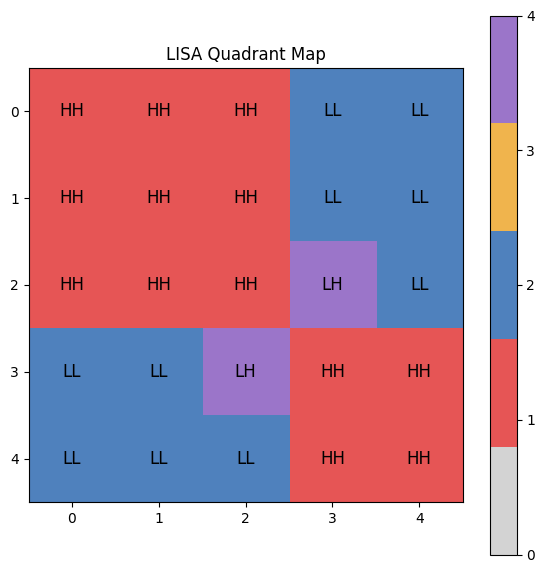

In [33]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

quad_map = quadrant.reshape(5, 5)

cmap = ListedColormap([
    "lightgray",  # 0
    "#e65555",   # 1 HH
    "#4f81bd",   # 2 LL
    "#f0b44d",   # 3 HL
    "#9b75c9"   # 4 LH
])

labels = {
    0: "-",
    1: "HH",
    2: "LL",
    3: "HL",
    4: "LH"
}

plt.figure(figsize=(7, 7))
plt.imshow(quad_map, cmap=cmap, vmin=0, vmax=4)

for r in range(5):
    for c in range(5):
        plt.text(
            c, r,
            labels[quad_map[r, c]],
            ha="center",
            va="center",
            fontsize=12
        )

plt.title("LISA Quadrant Map")
plt.xticks(range(5))
plt.yticks(range(5))
plt.colorbar(ticks=[0, 1, 2, 3, 4])
plt.show()

In [34]:
# LISA Significance Test
np.random.seed(42)

n_permutations = 999
n_cells = len(z)

p_values = np.zeros(n_cells)

In [35]:
rng = np.random.default_rng(42)

for i in range(n_cells):
    other_indices = np.arange(n_cells)
    other_indices = other_indices[other_indices != i] # only for neighbors, cell is fixed.

    other_values = z[other_indices]

    permuted_I = np.zeros(n_permutations)

    for p in range(n_permutations):
        perm_z = z.copy()

        perm_z[other_indices] = rng.permutation(other_values)

        perm_lag = W_mean[i] @ perm_z

        permuted_I[p] = z[i] * perm_lag

    p_values[i] = (
        1 + np.sum(np.abs(permuted_I) >= abs(local_I[i]))
    ) / (n_permutations + 1)

In [36]:
print(p_values)

[0.386 0.2   0.811 0.423 0.034 0.198 0.054 0.302 0.247 0.159 0.858 0.361
 0.93  0.702 0.725 0.331 0.193 0.794 0.741 0.485 0.042 0.118 0.574 0.529
 0.067]


In [37]:
significant_quadrant = quadrant.copy()

significant_quadrant[p_values >= 0.05] = 0

print(significant_quadrant.reshape(5, 5))

[[0 0 0 0 2]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [2 0 0 0 0]]


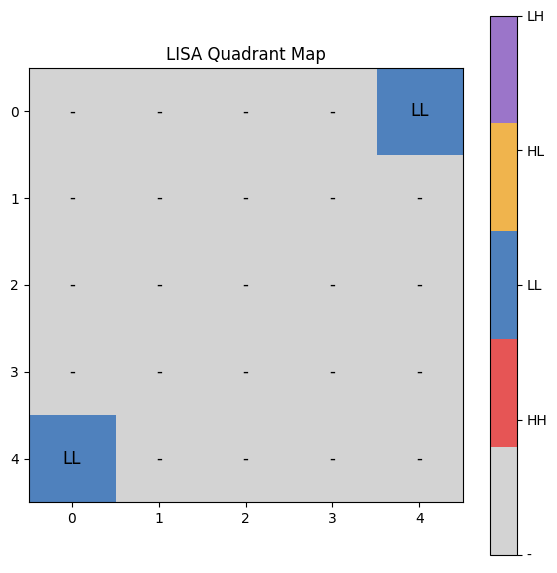

In [39]:
sig_quad_map = significant_quadrant.reshape(5, 5)

cmap = ListedColormap([
    "lightgray",  # 0
    "#e65555",   # 1 HH
    "#4f81bd",   # 2 LL
    "#f0b44d",   # 3 HL
    "#9b75c9"   # 4 LH
])

labels = {
    0: "-",
    1: "HH",
    2: "LL",
    3: "HL",
    4: "LH"
}

plt.figure(figsize=(7, 7))
plt.imshow(sig_quad_map, cmap=cmap, vmin=0, vmax=4)

for r in range(5):
    for c in range(5):
        plt.text(
            c, r,
            labels[sig_quad_map[r, c]],
            ha="center",
            va="center",
            fontsize=12
        )

plt.title("LISA Quadrant Map")
plt.xticks(range(5))
plt.yticks(range(5))
cbar = plt.colorbar(ticks=[0, 1, 2, 3, 4])
cbar.ax.set_yticklabels(["-", "HH", "LL", "HL", "LH"])
plt.show()